<a href="https://colab.research.google.com/github/KesharaGunathilaka/True-or-Lie-Detector-AI/blob/deploy/True_or_Lie_Detector_AI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Truth Or Lie Detector**

**Group Number:** 01

**Students:**

Gunarathne A.N.G.T.N.B

Rajapakshe R.M.M.L.D

Piyumantha H.D.D.B.A

Gunathilaka G.P.K.H

## Litreature Survey



* The task of automated deception detection has gained significant attention due to its potential in security, forensics, and human-computer interaction. Traditional lie detection is based on physiological measurements (e.g., polygraphs), which are intrusive and unreliable. Since the development of deep learning and computer vision, individuals have begun developing non-invasive methods from video data to detect dishonest behavior. In this project we are trying to applying Convolutional Neural Networks (CNNs) and Recurrent Neural Networks (RNNs) to classify truth and lie from videos.

* Early efforts in deception detection from video focused on facial expressions—brief, facial expressions revealing genuine emotions. Works like Ekman and Friesen (1978) laid the foundation for facial-based deception detection. However, manually extracting these expressions can be hard and problematic.

* CNNs have been widely used to extract spatial features from individual video frames. Zhang et al. (2017) applied CNNs on frame-level data to capture facial expressions and visual cues indicative of lying. Pre-trained models like VGGNet, ResNet, and FaceNet have shown effectiveness in capturing subtle facial muscle movements.

* Deception is typically a dynamic process. RNNs, particularly Long Short-Term Memory (LSTM) networks, are naturally capable of capturing the temporal dependencies and the dynamic patterns of behavior over time. Gupta and Chandra (2019) used CNN-LSTM architectures to capture how facial expressions and head movements vary along video sequences

### For this Project, the dataset consists of video clips labeled as "lie" or "truth." This dataset have used,

* Near-balanced classes: 440 lie / 389 truth clips (53.1% / 46.9%), cut from 59 lie and 50 truth source trials.

* Naturalistic conditions to replicate real-world scenarios.

* Preprocessing typically involves face detection, frame extraction, and sequence normalization for feeding into CNN-RNN pipelines.

* Because the 829 clips are cut from only 109 source trials, any split must group clips by their source trial. See "The Split Problem" in the README.

* Lie detection from video is a challenging but meaningful task. Techniques of deep learning, like CNNs and RNNs, have enabled tremendous progress in this direction. Strong feature extraction, explainable models, and real-time applicability are emerging research areas. In this project our motive is to use CNN, and RNN techniques to create a effective deception detection/ truth or lie detection model.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Dataset layout.
#
# DATA_ROOT is the single source of truth for every path below. The original
# version mixed an absolute extract path ("/content/data") with relative
# TRAIN_DIR / TEST_DIR values ("data/TruthOrLie/train"), which only worked
# because Colab's working directory happens to be /content.
import os
from zipfile import ZipFile

# Place the dataset archive in your Drive at this path. See README "Data Setup".
ZIP_PATH = "/content/drive/MyDrive/TruthOrLie.zip"
DATA_ROOT = "/content/data"

if not os.path.isdir(os.path.join(DATA_ROOT, "TruthOrLie")):
    with ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_ROOT)
    print("Unzipped to:", DATA_ROOT)
else:
    print("Dataset already extracted at:", DATA_ROOT)

TRAIN_DIR = os.path.join(DATA_ROOT, "TruthOrLie", "train")
TEST_DIR = os.path.join(DATA_ROOT, "TruthOrLie", "test")

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)

Unzipped to: /content/data


## Import Necessary Libraries

In [ ]:
# Standard library
import os
import pickle
import random
import subprocess
import uuid
from concurrent.futures import ThreadPoolExecutor
from datetime import timedelta

# Numerics and data
import numpy as np
import pandas as pd

# Media
import cv2
import librosa

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import (
    BatchNormalization, Conv1D, Dense, Dropout, Flatten, MaxPooling1D, SimpleRNN,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

# scikit-learn
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler

print("TensorFlow:", tf.__version__)
print("librosa   :", librosa.__version__)

In [ ]:
# Make the repository's src/ package importable.
#
# extract_frames(), extract_audio_features(), check_ffmpeg(), trial_id() and
# group_split() live in src/preprocessing.py rather than inline in this
# notebook, so that tests/ can exercise them without a GPU or the dataset.
# There is exactly one definition of each.
import sys

REPO_URL = "https://github.com/KesharaGunathilaka/True-or-Lie-Detector-AI.git"
REPO_DIR = "/content/True-or-Lie-Detector-AI" if os.path.isdir("/content") else os.getcwd()

if not os.path.isdir(os.path.join(REPO_DIR, "src")):
    # Running on a fresh Colab runtime: fetch the repo for its src/ package.
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", "deploy", REPO_URL, REPO_DIR],
        check=True,
    )

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.preprocessing import (
    AUDIO_FEATURE_DIM,
    FRAME_HEIGHT,
    FRAME_WIDTH,
    NUM_FRAMES,
    check_ffmpeg,
    extract_audio_features,
    extract_frames,
    group_split,
    trial_id,
)

print("Loaded helpers from", os.path.join(REPO_DIR, "src", "preprocessing.py"))

## Dataset Description

In [ ]:
def get_dataset_info(directory, sample_per_class=5):
    """Summarise one dataset split.

    Args:
        directory: split root containing one subdirectory per class.
        sample_per_class: how many videos per class to probe for duration and
            resolution statistics. Class counts are always exact; only the
            stats are sampled, because probing all ~800 clips means opening
            and seeking every file.

    Returns:
        dict with 'class_counts' (exact) plus 'durations', 'frame_counts' and
        'resolutions' gathered from the sampled videos. The original version
        built these three lists and then discarded them by returning only the
        counts.
    """
    classes = [d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))]

    class_counts = {}
    video_durations = []
    frame_counts = []
    resolutions = []

    for cls in classes:
        class_dir = os.path.join(directory, cls)
        videos = [v for v in os.listdir(class_dir) if v.endswith((".mp4", ".avi", ".mov"))]
        class_counts[cls] = len(videos)

        for video_file in videos[:sample_per_class]:
            video_path = os.path.join(class_dir, video_file)
            cap = cv2.VideoCapture(video_path)
            try:
                if not cap.isOpened():
                    print(f"Could not open {video_file}")
                    continue

                fps = cap.get(cv2.CAP_PROP_FPS)
                frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
                width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
                height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

                video_durations.append(frame_count / fps if fps > 0 else 0)
                frame_counts.append(frame_count)
                resolutions.append((width, height))
            except Exception as exc:
                print(f"Error processing {video_file}: {exc}")
            finally:
                cap.release()

    return {
        "class_counts": class_counts,
        "durations": video_durations,
        "frame_counts": frame_counts,
        "resolutions": resolutions,
    }


train_info = get_dataset_info(TRAIN_DIR)
test_info = get_dataset_info(TEST_DIR)

train_counts = train_info["class_counts"]
test_counts = test_info["class_counts"]

combined_counts = {}
for cls in set(train_counts) | set(test_counts):
    combined_counts[cls] = train_counts.get(cls, 0) + test_counts.get(cls, 0)

print("\n=== DATASET SUMMARY ===")
print(f"Total videos: {sum(combined_counts.values())} videos")
print(f"Class distribution: {combined_counts}")

sampled_res = train_info["resolutions"]
if sampled_res:
    print(f"Sampled resolutions: {sorted(set(sampled_res))}")
    print(f"Sampled mean duration: {np.mean(train_info['durations']):.2f}s")


=== DATASET SUMMARY ===
Total videos: 829 videos
Class distribution: {'truth': 389, 'lie': 440}


(array([  0., 100., 200., 300., 400., 500.]),
 [Text(0, 0.0, '0'),
  Text(0, 100.0, '100'),
  Text(0, 200.0, '200'),
  Text(0, 300.0, '300'),
  Text(0, 400.0, '400'),
  Text(0, 500.0, '500')])

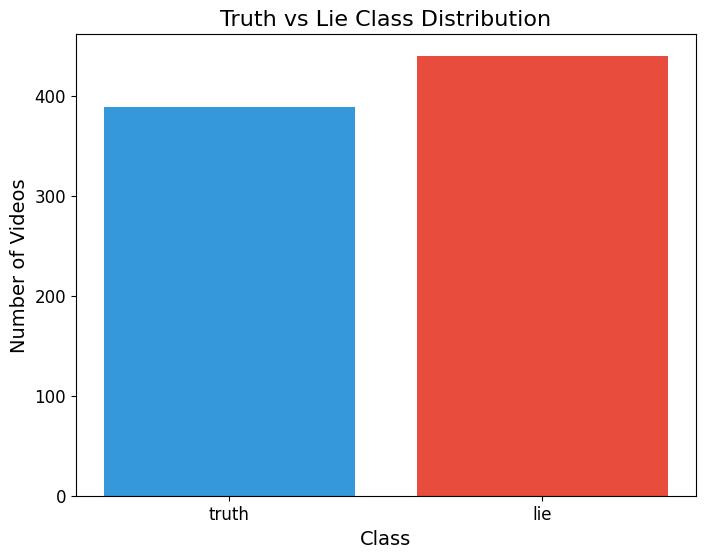

In [ ]:
plt.figure(figsize=(8, 6))
classes = list(combined_counts.keys())
counts = [combined_counts[cls] for cls in classes]

plt.bar(classes, counts, color=['#3498db', '#e74c3c'])
plt.xlabel('Class', fontsize=14)
plt.ylabel('Number of Videos', fontsize=14)
plt.title('Truth vs Lie Class Distribution', fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

In [ ]:

total = sum(combined_counts.values())
for cls in classes:
    percentage = (combined_counts[cls] / total) * 100
    print(f"{cls}: {combined_counts[cls]} videos ({percentage:.1f}%)")

truth: 389 videos (46.9%)
lie: 440 videos (53.1%)


In [ ]:
def visualize_sample_video(directory, class_name=None, num_samples=1, display_frames=4):
    """
    Visualize a sample video from the dataset with basic information.

    Args:
        directory: Path to the dataset directory
        class_name: Specific class to sample from (if None, randomly selects a class)
        num_samples: Number of videos to sample
        display_frames: Number of frames to extract and display from each video

    Returns:
        None (displays the visualization)
    """
    # os, cv2, numpy, plt, random and timedelta are imported at the top of
    # the notebook; the original re-imported them inside this function.

    # Get classes
    classes = [d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))]

    if not classes:
        print("No classes found in the directory.")
        return

    # If class_name is not specified, randomly select from available classes
    if class_name is None:
        selected_classes = random.sample(classes, min(num_samples, len(classes)))
    else:
        if class_name in classes:
            selected_classes = [class_name] * num_samples
        else:
            print(f"Class '{class_name}' not found. Available classes: {classes}")
            return

    for i, cls in enumerate(selected_classes):
        class_dir = os.path.join(directory, cls)
        videos = [v for v in os.listdir(class_dir) if v.lower().endswith(('.mp4', '.avi', '.mov', '.mkv', '.webm', '.flv'))]

        if not videos:
            print(f"No videos found in class '{cls}'.")
            continue

        # Randomly select a video
        video_file = random.choice(videos)
        video_path = os.path.join(class_dir, video_file)

        try:
            # Open video
            cap = cv2.VideoCapture(video_path)
            if not cap.isOpened():
                print(f"Could not open video {video_file}")
                continue

            # Get video properties
            fps = cap.get(cv2.CAP_PROP_FPS)
            frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
            height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
            duration = frame_count / fps if fps > 0 else 0
            file_size_mb = os.path.getsize(video_path) / (1024 * 1024)

            # Extract frames at regular intervals
            frames = []
            if frame_count > 0:
                interval = frame_count // (display_frames + 1)
                for j in range(1, display_frames + 1):
                    cap.set(cv2.CAP_PROP_POS_FRAMES, j * interval)
                    ret, frame = cap.read()
                    if ret:
                        # Convert BGR to RGB
                        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                        frames.append(frame)

            cap.release()

            # Display the information and frames
            plt.figure(figsize=(14, 8))

            # Video info section
            plt.subplot(2, 1, 1)
            plt.axis('off')
            info_text = f"""
            VIDEO INFORMATION:
            -------------------
            Class: {cls}
            Filename: {video_file}
            Resolution: {width}x{height}
            Duration: {timedelta(seconds=int(duration))}
            FPS: {fps:.2f}
            Total Frames: {frame_count}
            File Size: {file_size_mb:.2f} MB
            """
            plt.text(0.1, 0.1, info_text, fontsize=12, family='monospace')
            plt.title(f"Sample Video from Class: {cls}", fontsize=14)

            # Display frames
            if frames:
                plt.subplot(2, 1, 2)
                for j, frame in enumerate(frames):
                    plt.subplot(2, len(frames), len(frames) + j + 1)
                    plt.imshow(frame)
                    frame_number = (j + 1) * interval
                    timestamp = frame_number / fps if fps > 0 else 0
                    plt.title(f"Frame {frame_number}\n({timestamp:.2f}s)")
                    plt.axis('off')

            plt.tight_layout()
            plt.show()

            print(f"\nVideo Preview: {video_file}")
            print("="*50)
            print(f"Class: {cls}")
            print(f"Resolution: {width}x{height}")
            print(f"Duration: {timedelta(seconds=int(duration))}")
            print(f"FPS: {fps:.2f}")
            print(f"Total Frames: {frame_count}")
            print(f"File Size: {file_size_mb:.2f} MB")
            print("="*50)

        except Exception as e:
            print(f"Error processing {video_file}: {str(e)}")


In [ ]:
visualize_sample_video(TRAIN_DIR)

## Exploratory Data Analysis (EDA)

In [ ]:
# Scratch directory for audio demuxed during EDA. The preprocessing stage
# later uses its own OUTPUT_DIR; this keeps the two independent so the EDA
# cells can run standalone.
EDA_TEMP_DIR = "eda_temp"

# Loaded once at module scope. The original constructed this classifier from
# disk inside the per-frame loop, i.e. ~10 times per video and roughly 8,290
# times over the full dataset.
FACE_CASCADE = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)


def extract_video_features(video_path):
    """Extract summary visual and audio statistics from one video (EDA only)."""
    try:
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            return None

        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        duration = frame_count / fps if fps > 0 else 0

        frames_to_sample = min(10, frame_count)
        frame_indices = np.linspace(0, frame_count - 1, frames_to_sample, dtype=int)

        avg_brightness = []
        motion_metrics = []
        face_metrics = []
        prev_frame = None

        for i in frame_indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
            ret, frame = cap.read()
            if not ret:
                continue

            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            avg_brightness.append(np.mean(gray))

            if prev_frame is not None:
                motion_metrics.append(np.mean(cv2.absdiff(prev_frame, gray)))

            try:
                faces = FACE_CASCADE.detectMultiScale(gray, 1.1, 4)
                if len(faces) > 0:
                    x, y_box, w, h = faces[0]
                    face_metrics.append(w * h / (width * height))
            except Exception as exc:
                # Narrowed from a bare `except:`, which also swallowed
                # KeyboardInterrupt and made long runs impossible to stop.
                print(f"Face detection failed on a frame of {video_path}: {exc}")

            prev_frame = gray

        cap.release()

        # Audio is demuxed via subprocess with list arguments and a unique
        # per-call filename. The original used os.system() with an unquoted
        # f-string (any space or shell metacharacter in a path broke it, or
        # worse) and a single shared "temp_audio.wav" that all four worker
        # threads raced to write and delete.
        audio_features = {}
        temp_audio = os.path.join(EDA_TEMP_DIR, f"temp_audio_{uuid.uuid4().hex}.wav")
        try:
            os.makedirs(EDA_TEMP_DIR, exist_ok=True)
            subprocess.run(
                ["ffmpeg", "-i", video_path, "-q:a", "0", "-map", "a", temp_audio, "-y"],
                stdout=subprocess.PIPE, stderr=subprocess.PIPE, check=True,
            )
            samples, sr = librosa.load(temp_audio)
            audio_features["audio_length"] = len(samples) / sr
            audio_features["zero_crossing_rate"] = np.mean(librosa.feature.zero_crossing_rate(samples))
            audio_features["spectral_centroid"] = np.mean(librosa.feature.spectral_centroid(y=samples, sr=sr))
            audio_features["spectral_rolloff"] = np.mean(librosa.feature.spectral_rolloff(y=samples, sr=sr))
            audio_features["mfccs"] = np.mean(librosa.feature.mfcc(y=samples, sr=sr))
        except (subprocess.CalledProcessError, FileNotFoundError):
            pass  # No audio stream, or ffmpeg unavailable: leave the fields absent.
        except Exception as exc:
            print(f"Audio feature extraction failed for {video_path}: {exc}")
        finally:
            try:
                os.remove(temp_audio)
            except OSError:
                pass

        features = {
            "fps": fps,
            "duration": duration,
            "frame_count": frame_count,
            "resolution": f"{width}x{height}",
            "avg_brightness": np.mean(avg_brightness) if avg_brightness else None,
            "brightness_std": np.std(avg_brightness) if avg_brightness else None,
            "motion_avg": np.mean(motion_metrics) if motion_metrics else None,
            "motion_std": np.std(motion_metrics) if motion_metrics else None,
            "face_area_avg": np.mean(face_metrics) if face_metrics else None,
            "face_detected": len(face_metrics) > 0,
        }
        features.update(audio_features)
        return features

    except Exception as exc:
        print(f"Error processing {video_path}: {exc}")
        return None

In [ ]:
def process_dataset(directory, dataset_name):
    """Process all videos in a dataset and create a dataframe with source information."""
    all_data = []


    classes = [d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))]

    for cls in classes:
        class_dir = os.path.join(directory, cls)
        videos = [v for v in os.listdir(class_dir) if v.endswith(('.mp4', '.avi', '.mov'))]

        print(f"Processing {len(videos)} videos in {dataset_name} class {cls}...")


        with ThreadPoolExecutor(max_workers=4) as executor:
            futures = []
            for video_file in videos:
                video_path = os.path.join(class_dir, video_file)
                futures.append(executor.submit(extract_video_features, video_path))

            for i, future in enumerate(tqdm(futures)):
                features = future.result()
                if features:
                    features["filename"] = videos[i]
                    features["class"] = cls
                    features["dataset"] = dataset_name
                    all_data.append(features)
    df = pd.DataFrame(all_data)
    return df


In [ ]:
print("Processing training dataset...")
train_df = process_dataset(TRAIN_DIR, "train")
train_df.to_csv('train_features.csv', index=False)
print(f"Training dataset: {len(train_df)} videos")


Processing training dataset...
Processing 385 videos in train class truth...


 29%|██▉       | 111/385 [05:24<13:10,  2.88s/it]<ipython-input-37-1687093f8176>:76: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(temp_audio)
/usr/local/lib/python3.11/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
 56%|█████▌    | 216/385 [09:34<05:28,  1.94s/it]/usr/local/lib/python3.11/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1536
  warnings.warn(
100%|██████████| 385/385 [15:20<00:00,  2.39s/it]


Processing 436 videos in train class lie...


100%|██████████| 436/436 [22:51<00:00,  3.15s/it]

Training dataset: 821 videos


In [ ]:
print("Processing test dataset...")
test_df = process_dataset(TEST_DIR, "test")
test_df.to_csv('test_features.csv', index=False)
print(f"Test dataset: {len(test_df)} videos")

Processing test dataset...
Processing 4 videos in test class truth...


100%|██████████| 4/4 [00:07<00:00,  1.76s/it]


Processing 4 videos in test class lie...


100%|██████████| 4/4 [00:06<00:00,  1.65s/it]

Test dataset: 8 videos


In [ ]:
combined_df = pd.concat([train_df, test_df], ignore_index=True)
combined_df.to_csv('combined_features.csv', index=False)
print(f"Combined dataset: {len(combined_df)} videos ({len(train_df)} from training, {len(test_df)} from test)")

Combined dataset: 829 videos (821 from training, 8 from test)


In [ ]:

print("\nBasic statistics for combined data:")
print(combined_df.describe())

print("\nMissing values in combined dataset:")
print(combined_df.isnull().sum())

print("\nClass distribution:")
print(combined_df['class'].value_counts())




Basic statistics for combined data:
              fps    duration  frame_count  avg_brightness  brightness_std  \
count  829.000000  829.000000   829.000000      829.000000      829.000000   
mean    26.921103    3.737271   100.632087       76.364582        1.338906   
std      6.585645    0.845072    33.916080       30.367937        4.230814   
min     10.000000    0.033333     1.000000       11.845327        0.000000   
25%     29.917000    3.903900    99.000000       68.377606        0.181635   
50%     29.970030    3.903900   117.000000       79.199161        0.352511   
75%     29.970030    4.204200   121.000000       91.465192        0.707265   
max     30.000000    4.500000   126.000000      176.811660       53.516356   

       motion_avg  motion_std  face_area_avg  audio_length  \
count  823.000000  823.000000     804.000000    812.000000   
mean     3.932578    2.344145       0.069445      3.710420   
std      4.057831    4.519081       0.067911      0.818661   
min      0.1

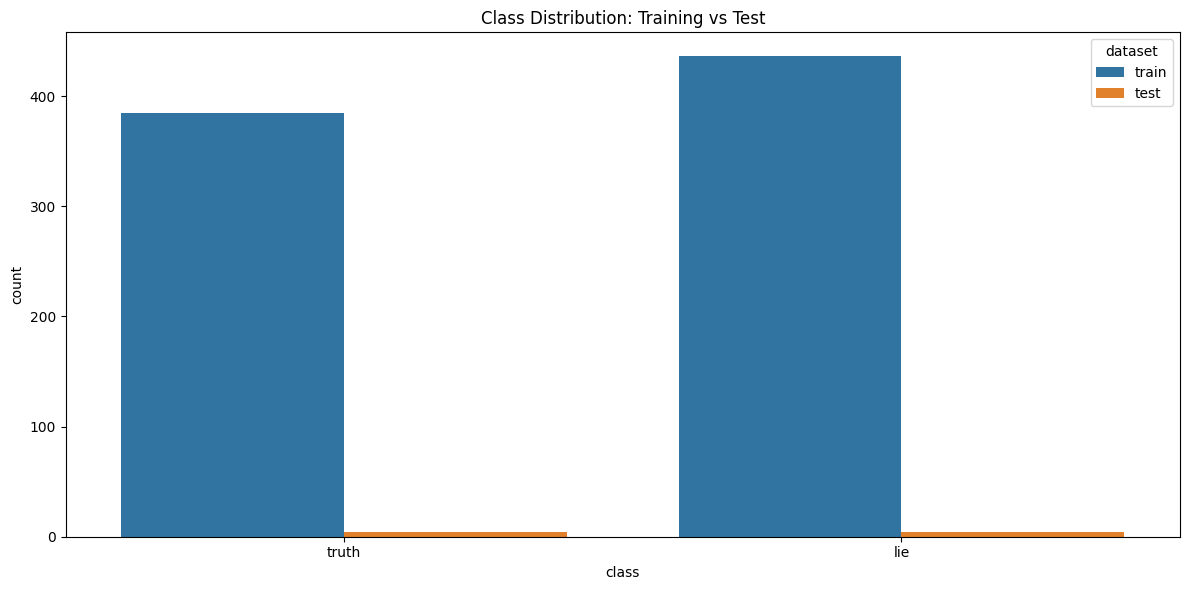

In [ ]:
plt.figure(figsize=(12, 6))
sns.countplot(x='class', data=combined_df, hue='dataset')
plt.title('Class Distribution: Training vs Test')
plt.tight_layout()
plt.savefig('class_distribution.png')
plt.show()

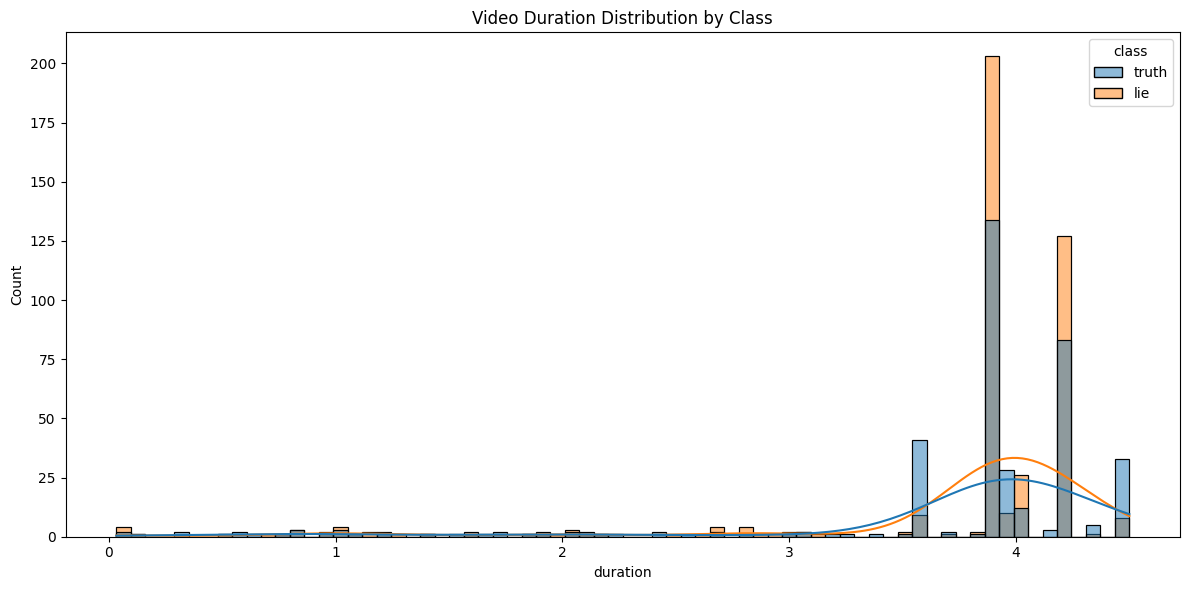

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(data=combined_df, x='duration', hue='class', kde=True)
plt.title('Video Duration Distribution by Class')
plt.tight_layout()
plt.savefig('duration_distribution.png')
plt.show()

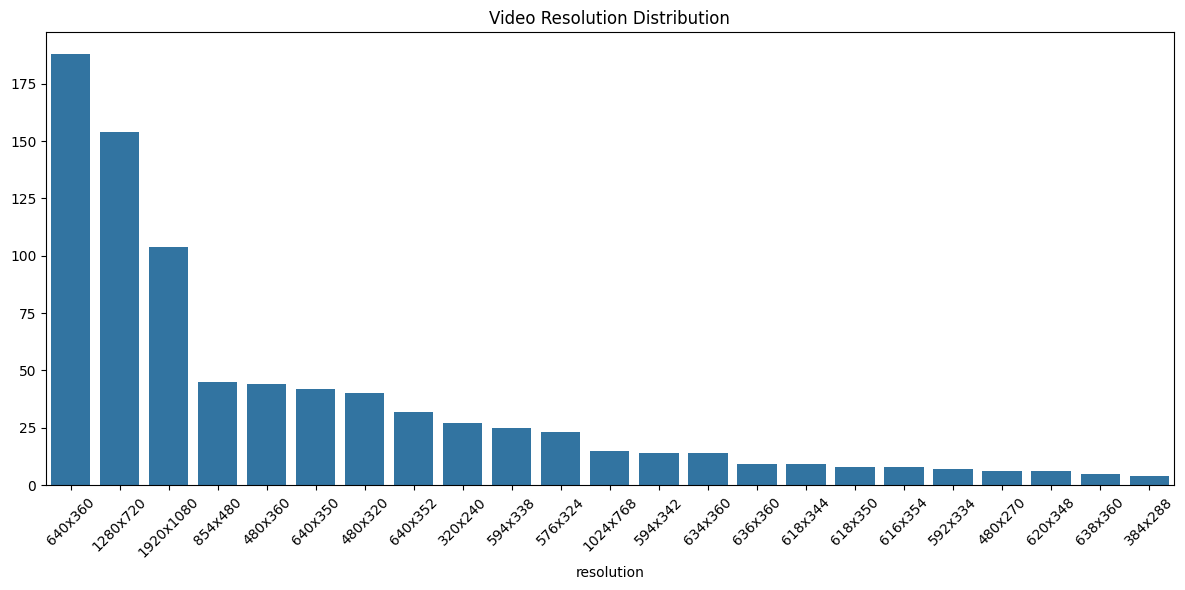

In [ ]:
resolution_count = combined_df['resolution'].value_counts()
plt.figure(figsize=(12, 6))
sns.barplot(x=resolution_count.index, y=resolution_count.values)
plt.title('Video Resolution Distribution')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('resolution_distribution.png')
plt.show()

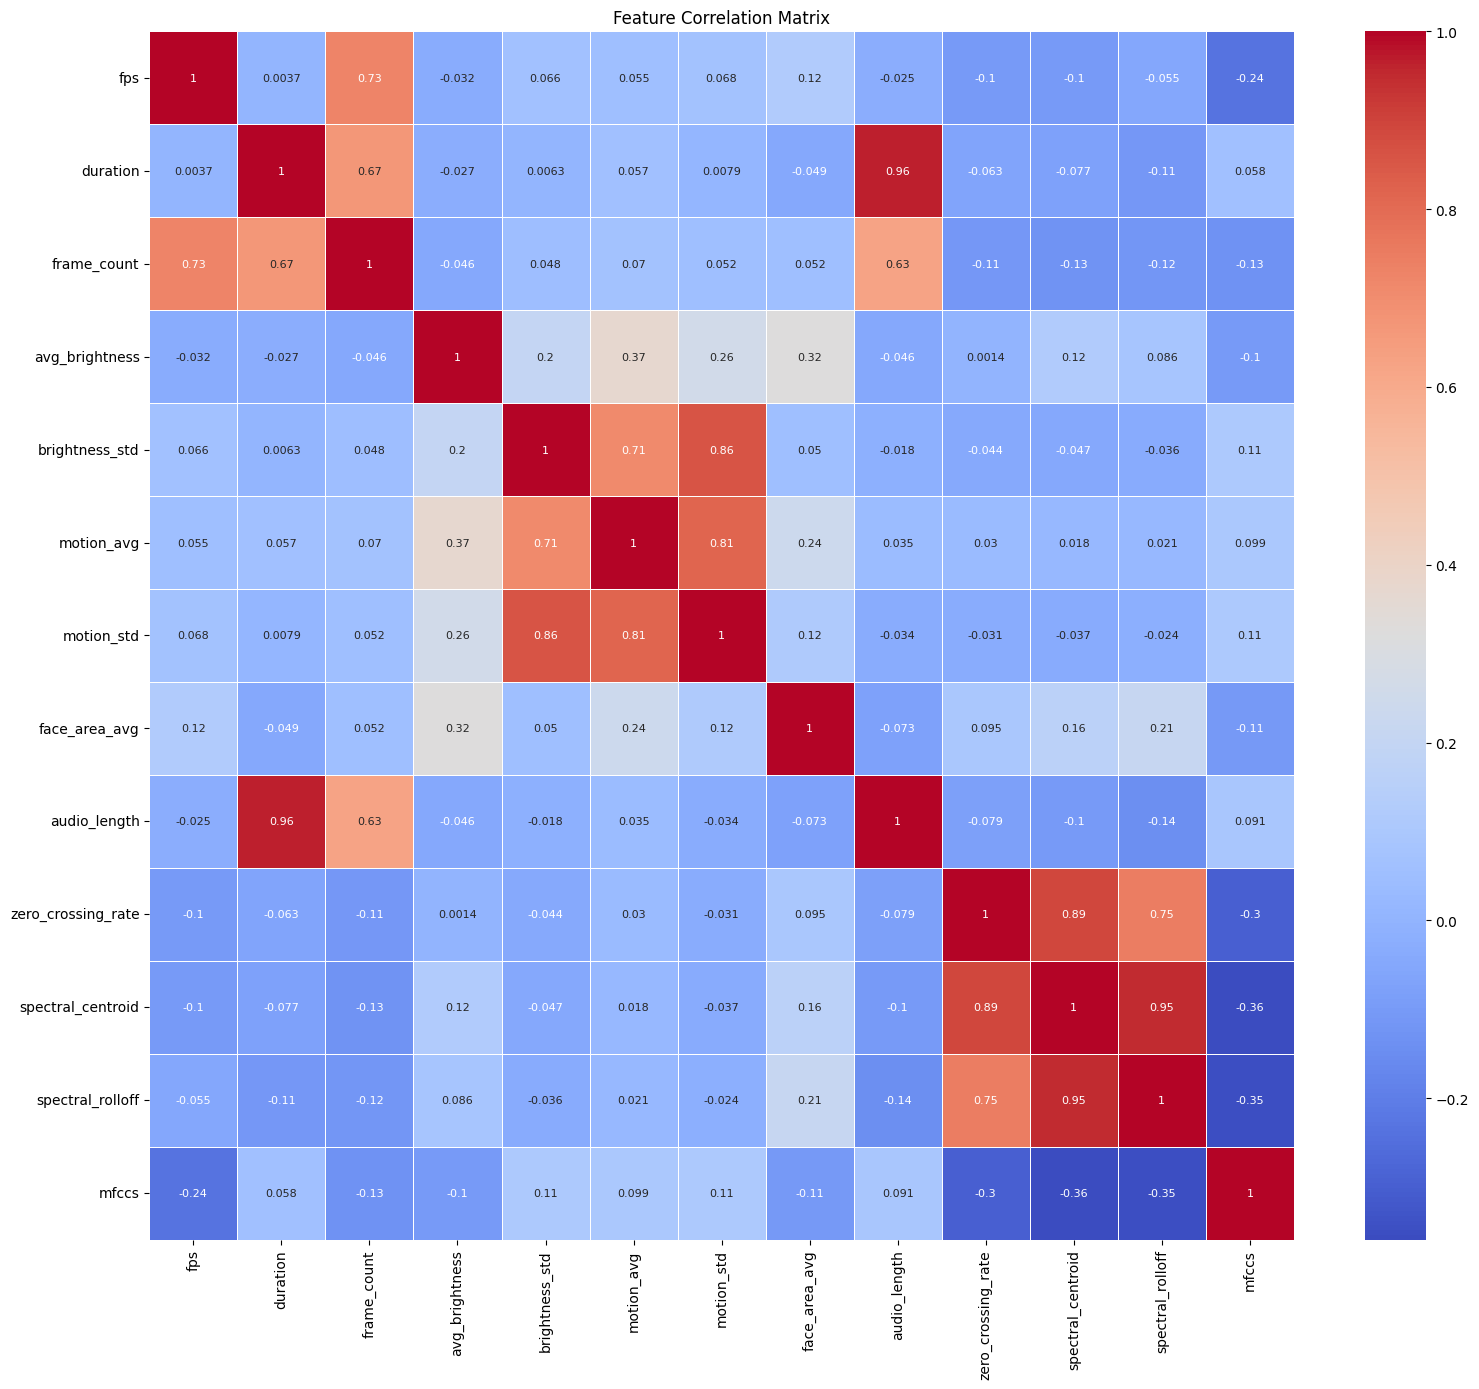

In [ ]:
numeric_cols = combined_df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(16, 14))
corr_matrix = combined_df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5, annot_kws={"size": 8})
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('feature_correlation.png')
plt.show()

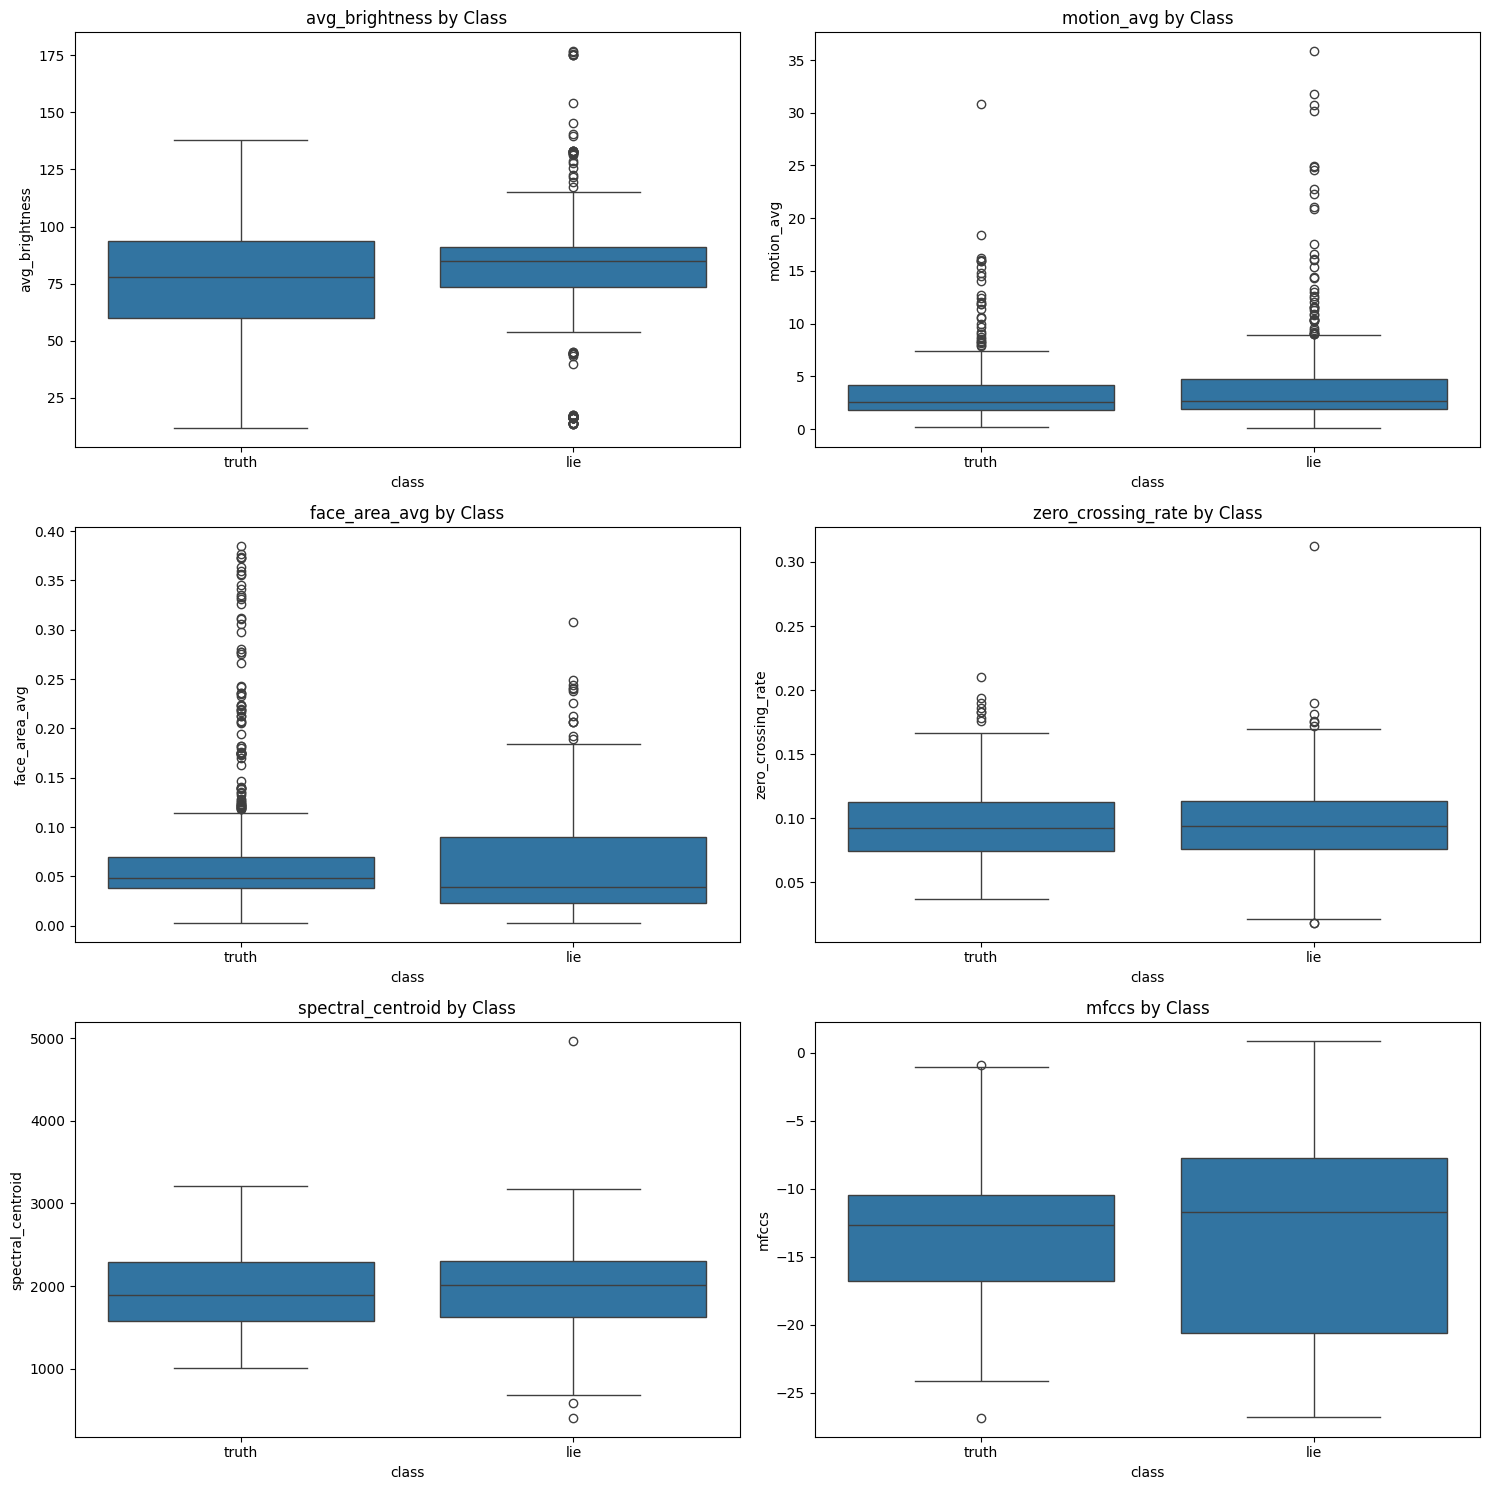

In [ ]:
features_to_plot = ['avg_brightness', 'motion_avg', 'face_area_avg',
                     'zero_crossing_rate', 'spectral_centroid', 'mfccs']

fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    if feature in combined_df.columns and i < len(axes):
        sns.boxplot(x='class', y=feature, data=combined_df, ax=axes[i])
        axes[i].set_title(f'{feature} by Class')

plt.tight_layout()
plt.savefig('feature_comparison.png')
plt.show()


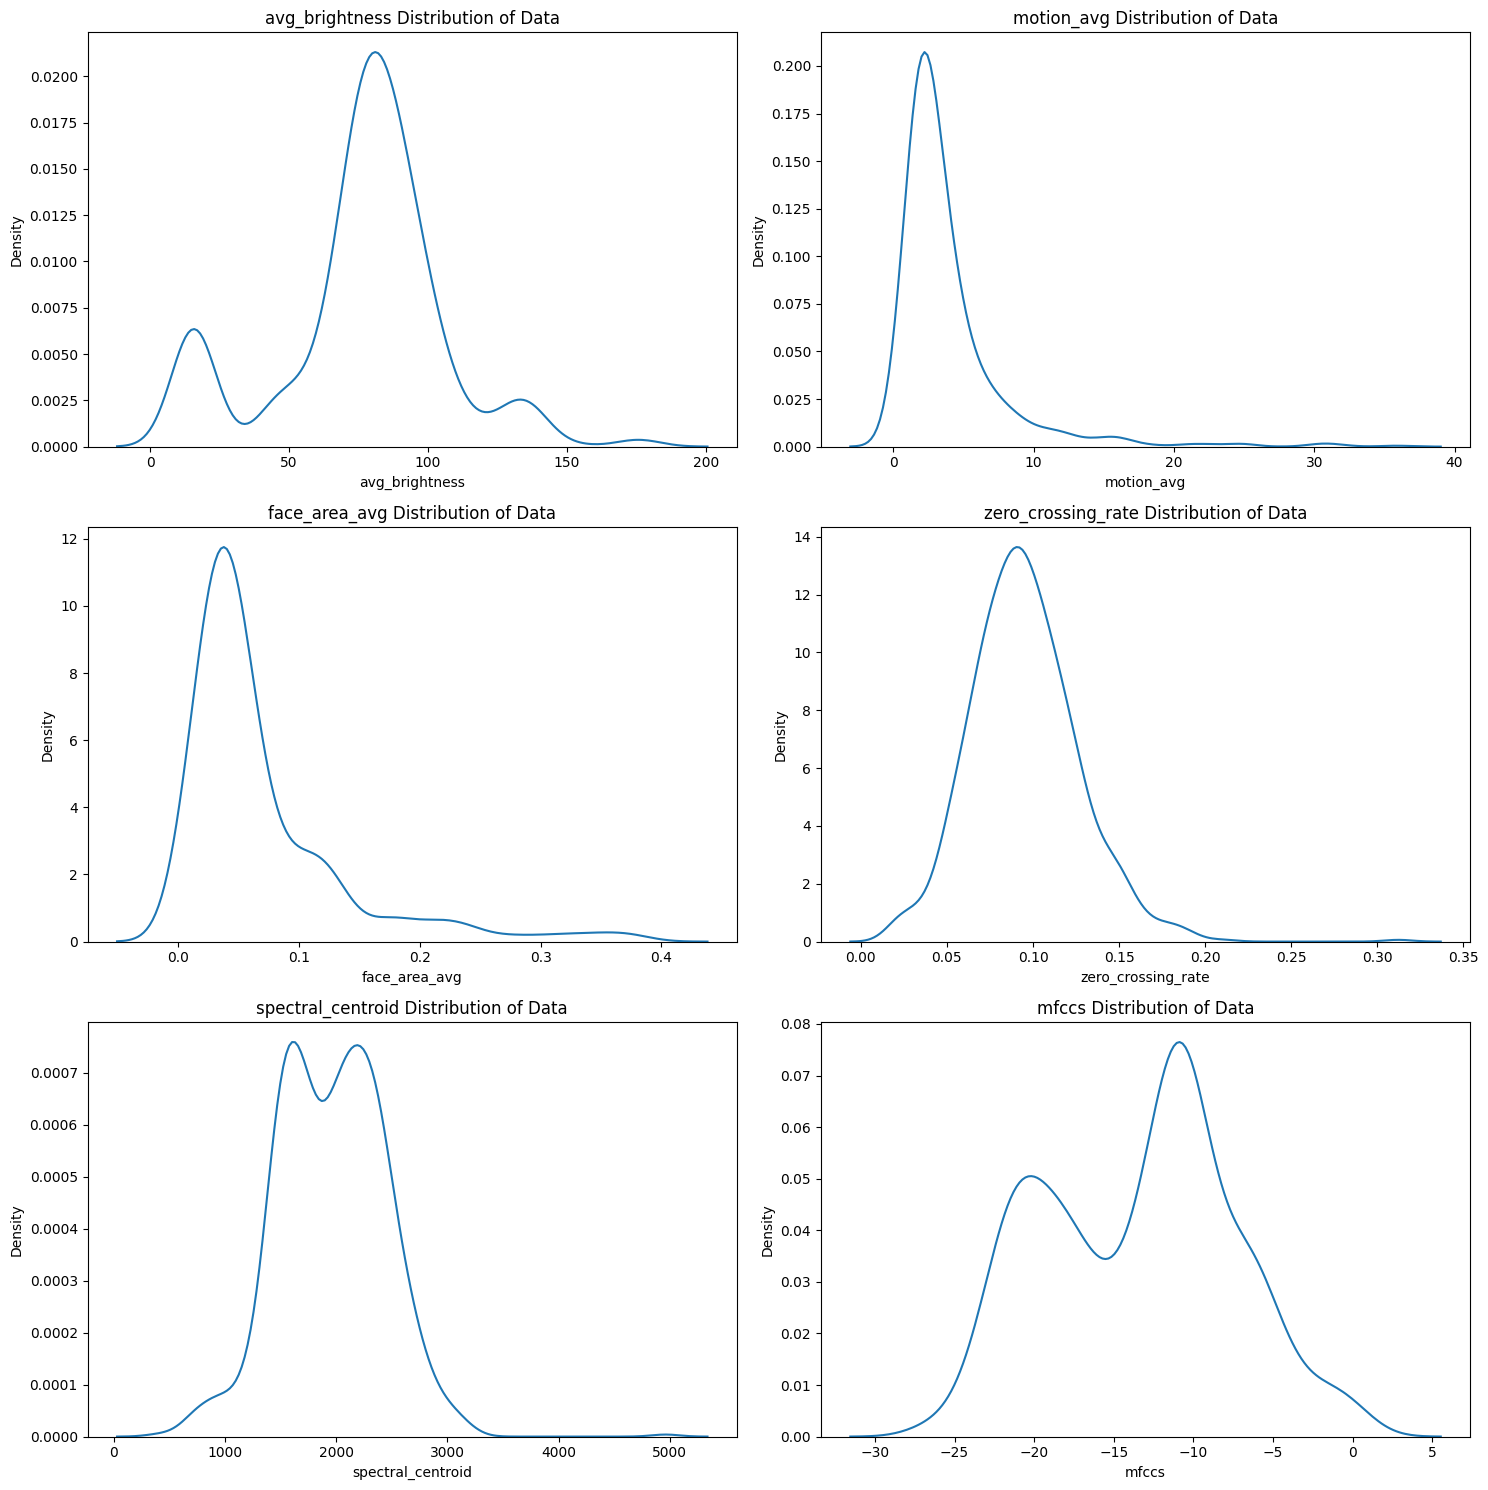

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    if feature in combined_df.columns and i < len(axes):
        sns.kdeplot(data=combined_df, x=feature, ax=axes[i])
        axes[i].set_title(f'{feature} Distribution of Data')

plt.tight_layout()
plt.savefig('train_test_distribution_comparison.png')
plt.show()




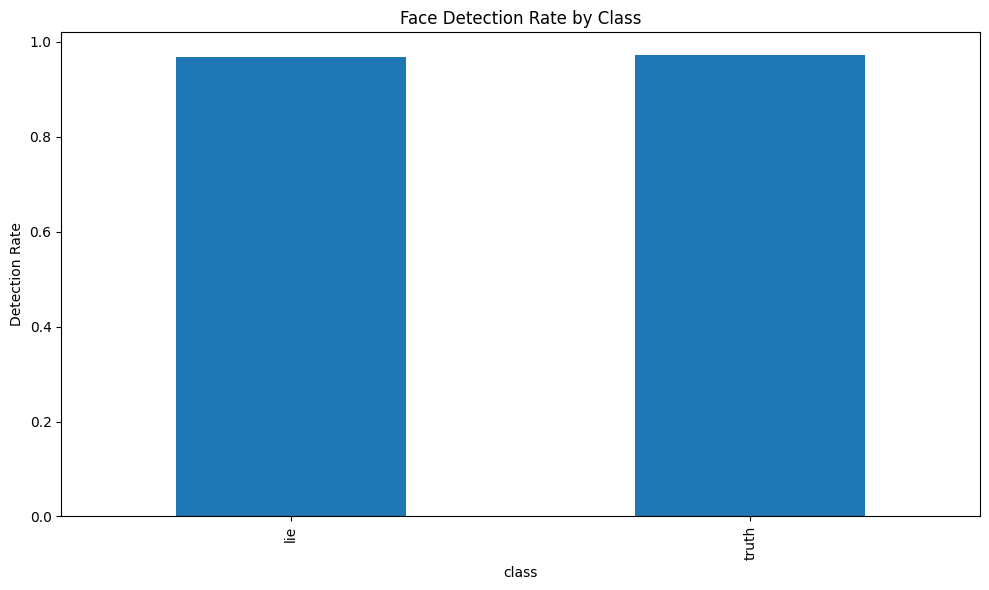

In [ ]:

plt.figure(figsize=(10, 6))
face_by_class = combined_df.groupby(['class'])['face_detected'].mean()
face_by_class.plot(kind='bar')
plt.title('Face Detection Rate by Class')
plt.ylabel('Detection Rate')
plt.tight_layout()
plt.savefig('face_detection_by_class.png')
plt.show()


Feature statistics by class:
fps: 15.20% difference between truth and lie
frame_count: 15.34% difference between truth and lie
avg_brightness: 9.47% difference between truth and lie
brightness_std: 81.79% difference between truth and lie
motion_avg: 19.15% difference between truth and lie
motion_std: 56.05% difference between truth and lie
face_area_avg: 31.21% difference between truth and lie


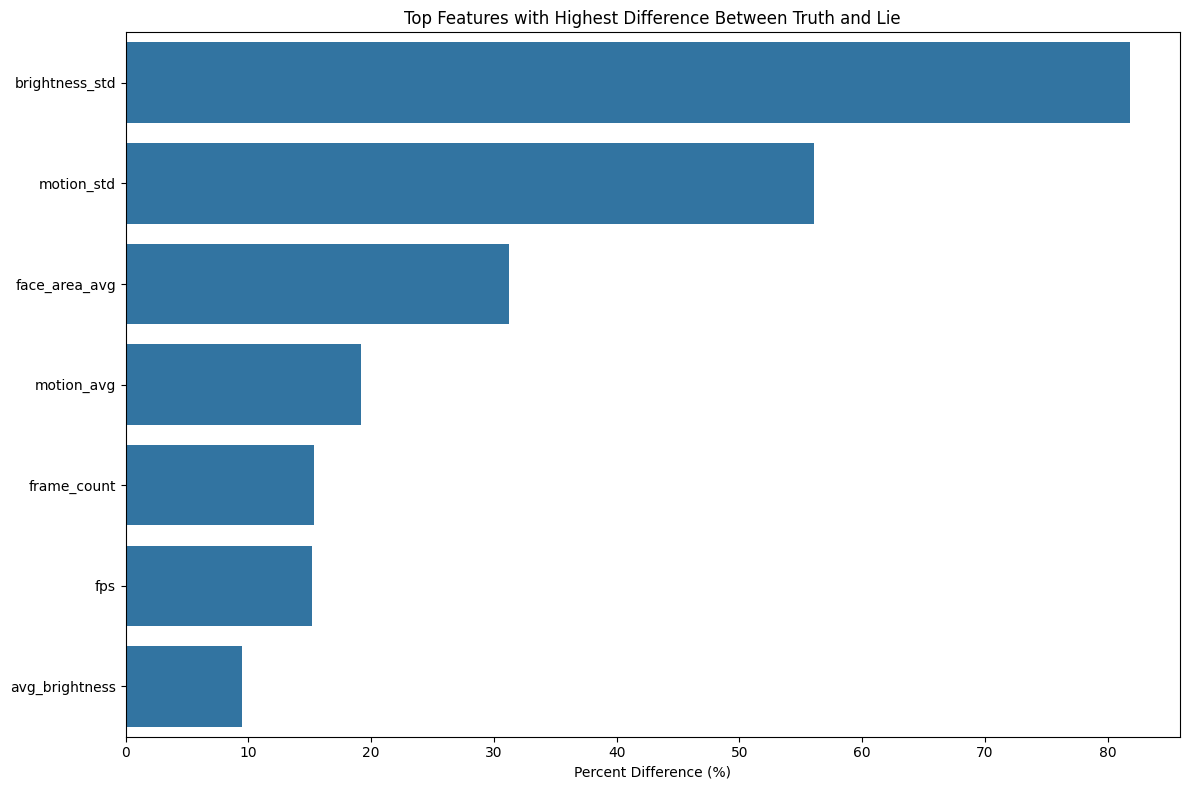

In [ ]:
numeric_cols = combined_df.select_dtypes(include=[np.number]).columns
significant_features = []

print("\nFeature statistics by class:")
for feature in numeric_cols:
    if feature in combined_df.columns:
        try:
            truth_mean = combined_df[combined_df['class'] == 'truth'][feature].mean()
            lie_mean = combined_df[combined_df['class'] == 'lie'][feature].mean()

            if not np.isnan(truth_mean) and not np.isnan(lie_mean) and (truth_mean + lie_mean) != 0:
                diff_percent = abs((truth_mean - lie_mean) / ((truth_mean + lie_mean) / 2) * 100)

                if not np.isnan(diff_percent) and diff_percent > 5:  # 5% difference threshold
                    significant_features.append((feature, diff_percent))
                    print(f"{feature}: {diff_percent:.2f}% difference between truth and lie")
        except (TypeError, ValueError) as exc:
            print(f"Skipping {feature}: {exc}")
            continue

if significant_features:
    significant_features.sort(key=lambda x: x[1], reverse=True)
    sig_features = [f[0] for f in significant_features[:min(10, len(significant_features))]]  # Top 10 features
    sig_diff = [f[1] for f in significant_features[:min(10, len(significant_features))]]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=sig_diff, y=sig_features)
    plt.title('Top Features with Highest Difference Between Truth and Lie')
    plt.xlabel('Percent Difference (%)')
    plt.tight_layout()
    plt.savefig('significant_features.png')
    plt.show()

## Data Preprocessing

Data preprocessing is the essential step of cleaning and transforming raw data into a structured and usable format. It involves tasks such as handling missing values, normalizing or scaling data, encoding categorical variables, and splitting datasets. Proper preprocessing improves data quality, ensures consistency, and enhances the performance and accuracy of machine learning models.

In [ ]:
# Output directory for every generated artifact (.npy / .pkl caches).
OUTPUT_DIR = "processed_data"
BATCH_SIZE = 32

os.makedirs(OUTPUT_DIR, exist_ok=True)

# NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH and AUDIO_FEATURE_DIM come from
# src/preprocessing.py so the notebook and the tests agree on one definition.
print(f"Frames per clip   : {NUM_FRAMES} @ {FRAME_WIDTH}x{FRAME_HEIGHT}")
print(f"Audio feature dim : {AUDIO_FEATURE_DIM}  (20 MFCC + 12 chroma + 128 mel + 7 contrast + 6 tonnetz)")
print(f"Artifacts         : {OUTPUT_DIR}/")

In [ ]:
# check_ffmpeg() lives in src/preprocessing.py. It now verifies the exit
# status too, so an ffmpeg that is installed but broken no longer passes a
# check that only caught FileNotFoundError.
print("ffmpeg available:", check_ffmpeg())

In [ ]:
# extract_frames() is imported from src/preprocessing.py.
#
# It samples NUM_FRAMES evenly spaced frames, resizes to 224x224 and converts
# BGR -> RGB, returning a fixed (30, 224, 224, 3) uint8 array for every clip so
# one unreadable file cannot break a batch of 800.
#
# It lives in src/ rather than inline so that tests/test_preprocessing.py can
# exercise it without a GPU or the 328 MB dataset.
help(extract_frames)

In [ ]:
# extract_audio_features() is imported from src/preprocessing.py.
#
# It demuxes audio with ffmpeg into a uniquely named temp WAV, then returns the
# concatenated per-coefficient means of five librosa feature families:
#   20 MFCC + 12 chroma + 128 mel + 7 spectral contrast + 6 tonnetz = 173 dims.
# Any failure returns a zero vector of exactly AUDIO_FEATURE_DIM width, so the
# caller's array shapes stay consistent.
help(extract_audio_features)

In [ ]:
def process_video(video_path, label):
    """Process a single video to extract frames and audio features."""
    frames = extract_frames(video_path)

    if frames is None:
        print(f"Skipping {video_path} due to frame extraction failure")
        return None

    audio_features = extract_audio_features(video_path)

    return {
        'frames': frames,
        'audio': audio_features,
        'label': label,
        'path': video_path
    }

In [ ]:
def preprocess_dataset(directory, output_prefix):
    """Process all videos in a directory and save features."""

    if not os.path.exists(directory):
        print(f"Error: Directory {directory} does not exist!")
        return None, None, None


    classes = [d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))]

    if not classes:
        print(f"No class subdirectories found in {directory}")
        return None, None, None

    print(f"Found classes: {classes}")


    label_encoder = LabelEncoder()
    label_encoder.fit(classes)

    results = []


    for cls in classes:
        class_dir = os.path.join(directory, cls)
        videos = [v for v in os.listdir(class_dir) if v.endswith(('.mp4', '.avi', '.mov'))]

        print(f"Processing {len(videos)} videos in class {cls}...")


        with ThreadPoolExecutor(max_workers=4) as executor:
            futures = []
            for video_file in videos:
                video_path = os.path.join(class_dir, video_file)
                label = label_encoder.transform([cls])[0]
                futures.append(executor.submit(process_video, video_path, label))

            for future in tqdm(futures):
                result = future.result()
                if result:
                    results.append(result)

    if not results:
        print(f"No videos were successfully processed in {directory}")
        return None, None, None

    print(f"Successfully processed {len(results)} videos from {directory}")

    frame_data = np.array([r['frames'] for r in results])
    audio_data = np.array([r['audio'] for r in results])
    labels = np.array([r['label'] for r in results])
    paths = [r['path'] for r in results]


    np.save(os.path.join(OUTPUT_DIR, f"{output_prefix}_frames.npy"), frame_data)
    np.save(os.path.join(OUTPUT_DIR, f"{output_prefix}_audio.npy"), audio_data)
    np.save(os.path.join(OUTPUT_DIR, f"{output_prefix}_labels.npy"), labels)

    with open(os.path.join(OUTPUT_DIR, f"{output_prefix}_paths.pkl"), 'wb') as f:
        pickle.dump(paths, f)

    if output_prefix == "train":
        with open(os.path.join(OUTPUT_DIR, "label_encoder.pkl"), 'wb') as f:
            pickle.dump(label_encoder, f)

    print(f"Processed {len(results)} videos. Data saved to {OUTPUT_DIR}")
    return frame_data, audio_data, labels

In [ ]:
def extract_features_with_pretrained_model():
    """Extract deep features using a pretrained model."""
    train_path = os.path.join(OUTPUT_DIR, "train_frames.npy")
    test_path = os.path.join(OUTPUT_DIR, "test_frames.npy")

    if not (os.path.exists(train_path) and os.path.exists(test_path)):
        print("Error: Processed frame files not found. Run preprocessing first.")
        return None, None

    try:
        base_model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg',
                               input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3))
    except Exception as e:
        print(f"Error loading MobileNetV2 model: {str(e)}")
        return None, None

    # Memory-mapped: the full training array is
    # 821 x 30 x 224 x 224 x 3 uint8 ~= 11 GB. Loading it eagerly only survives
    # on a high-RAM runtime; mmap lets us page in one BATCH_SIZE slice at a time.
    train_frames = np.load(train_path, mmap_mode="r")
    test_frames = np.load(test_path, mmap_mode="r")

    n_train = train_frames.shape[0]
    n_test = test_frames.shape[0]
    n_frames = train_frames.shape[1]

    train_features = []
    print("Extracting features from training frames...")
    for i in tqdm(range(0, n_train, BATCH_SIZE)):
        batch = np.asarray(train_frames[i:i+BATCH_SIZE])  # materialise just this slice
        batch_size = batch.shape[0]

        batch_reshaped = batch.reshape(-1, FRAME_HEIGHT, FRAME_WIDTH, 3)
        batch_preprocessed = preprocess_input(batch_reshaped.astype(np.float32))

        batch_features = base_model.predict(batch_preprocessed, verbose=0)

        batch_features = batch_features.reshape(batch_size, n_frames, -1)

        train_features.append(batch_features)

    if not train_features:
        print("Error: No training features extracted")
        return None, None

    train_features = np.vstack(train_features)

    test_features = []
    print("Extracting features from test frames...")
    for i in tqdm(range(0, n_test, BATCH_SIZE)):
        batch = np.asarray(test_frames[i:i+BATCH_SIZE])  # materialise just this slice
        batch_size = batch.shape[0]

        batch_reshaped = batch.reshape(-1, FRAME_HEIGHT, FRAME_WIDTH, 3)
        batch_preprocessed = preprocess_input(batch_reshaped.astype(np.float32))

        batch_features = base_model.predict(batch_preprocessed, verbose=0)

        batch_features = batch_features.reshape(batch_size, n_frames, -1)

        test_features.append(batch_features)

    if not test_features:
        print("Error: No test features extracted")
        return train_features, None

    test_features = np.vstack(test_features)

    np.save(os.path.join(OUTPUT_DIR, "train_deep_features.npy"), train_features)
    np.save(os.path.join(OUTPUT_DIR, "test_deep_features.npy"), test_features)

    print(f"Deep features extracted and saved. Shape: {train_features.shape}")
    return train_features, test_features

In [ ]:
SAVE_SEQUENCE_FEATURES = True  # keep the (30, 1280) tensors for a future temporal model


def combine_features():
    """Combine deep visual features with audio features."""
    required_files = [
        "train_deep_features.npy", "test_deep_features.npy",
        "train_audio.npy", "test_audio.npy",
        "train_labels.npy", "test_labels.npy"
    ]

    for file in required_files:
        if not os.path.exists(os.path.join(OUTPUT_DIR, file)):
            print(f"Error: Required file {file} not found in {OUTPUT_DIR}.")
            return None, None, None, None

    train_deep = np.load(os.path.join(OUTPUT_DIR, "train_deep_features.npy"))
    test_deep = np.load(os.path.join(OUTPUT_DIR, "test_deep_features.npy"))
    train_audio = np.load(os.path.join(OUTPUT_DIR, "train_audio.npy"))
    test_audio = np.load(os.path.join(OUTPUT_DIR, "test_audio.npy"))
    train_labels = np.load(os.path.join(OUTPUT_DIR, "train_labels.npy"))
    test_labels = np.load(os.path.join(OUTPUT_DIR, "test_labels.npy"))

    # IMPORTANT: this mean collapses the 30-frame axis, so everything
    # downstream sees one 1280-d vector per clip with no temporal ordering.
    # That is why the "RNN" in this notebook is not actually modelling time:
    # it receives shape (1453, 1), a sequence over feature *indices*.
    # The un-pooled (30, 1280) tensors are saved below so a genuine sequence
    # model can be trained on them without re-running feature extraction.
    train_deep_avg = np.mean(train_deep, axis=1)
    test_deep_avg = np.mean(test_deep, axis=1)

    if SAVE_SEQUENCE_FEATURES:
        np.save(os.path.join(OUTPUT_DIR, "train_deep_sequence.npy"), train_deep)
        np.save(os.path.join(OUTPUT_DIR, "test_deep_sequence.npy"), test_deep)
        print(f"Saved un-pooled sequence features: {train_deep.shape}")

    scaler = StandardScaler()
    train_deep_scaled = scaler.fit_transform(train_deep_avg)
    test_deep_scaled = scaler.transform(test_deep_avg)

    audio_scaler = StandardScaler()
    train_audio_scaled = audio_scaler.fit_transform(train_audio)
    test_audio_scaled = audio_scaler.transform(test_audio)

    train_combined = np.hstack([train_deep_scaled, train_audio_scaled])
    test_combined = np.hstack([test_deep_scaled, test_audio_scaled])

    with open(os.path.join(OUTPUT_DIR, "deep_scaler.pkl"), 'wb') as f:
        pickle.dump(scaler, f)

    with open(os.path.join(OUTPUT_DIR, "audio_scaler.pkl"), 'wb') as f:
        pickle.dump(audio_scaler, f)

    np.save(os.path.join(OUTPUT_DIR, "train_combined_features.npy"), train_combined)
    np.save(os.path.join(OUTPUT_DIR, "test_combined_features.npy"), test_combined)

    with open(os.path.join(OUTPUT_DIR, "label_encoder.pkl"), 'rb') as f:
        label_encoder = pickle.load(f)

    num_classes = len(label_encoder.classes_)
    train_labels_onehot = to_categorical(train_labels, num_classes)
    test_labels_onehot = to_categorical(test_labels, num_classes)

    np.save(os.path.join(OUTPUT_DIR, "train_labels_onehot.npy"), train_labels_onehot)
    np.save(os.path.join(OUTPUT_DIR, "test_labels_onehot.npy"), test_labels_onehot)

    print(f"Combined features created with shape: {train_combined.shape}")
    print(f"Classes: {label_encoder.classes_}")
    return train_combined, test_combined, train_labels_onehot, test_labels_onehot


In [ ]:
def main():
    """Main preprocessing function."""
    print("Starting preprocessing...")

    if not check_ffmpeg():
        return None

    if not os.path.exists(TRAIN_DIR):
        print(f"Error: Training directory {TRAIN_DIR} does not exist.")
        return None

    if not os.path.exists(TEST_DIR):
        print(f"Error: Test directory {TEST_DIR} does not exist.")
        return None

    print("\nProcessing training data...")
    train_frames, train_audio, train_labels = preprocess_dataset(TRAIN_DIR, "train")

    if train_frames is None:
        print("Training data preprocessing failed. Exiting.")
        return None

    print("\nProcessing test data...")
    test_frames, test_audio, test_labels = preprocess_dataset(TEST_DIR, "test")

    if test_frames is None:
        print("Test data preprocessing failed. Exiting.")
        return None

    print("\nExtracting deep features...")
    train_deep, test_deep = extract_features_with_pretrained_model()

    if train_deep is None:
        print("Feature extraction failed. Exiting.")
        return None

    print("\nCombining features...")
    train_combined, test_combined, train_labels_onehot, test_labels_onehot = combine_features()

    if train_combined is None:
        print("Feature combination failed. Exiting.")
        return None

    print("\nPreprocessing complete! Ready for model training.")
    print(f"Training data: {train_combined.shape}, Labels: {train_labels_onehot.shape}")
    print(f"Test data: {test_combined.shape}, Labels: {test_labels_onehot.shape}")

    return train_combined, test_combined, train_labels_onehot, test_labels_onehot


## Model Implementation (CNN)

In [ ]:
# ---------------------------------------------------------------------------
# CNN head.
#
# Names are suffixed _cnn / _rnn throughout. The original defined
# `train_model`, `evaluate_model` and `plot_training_results` twice -- once
# here and once in the RNN section -- so re-running cells out of order
# silently trained whichever model happened to be defined last.
# ---------------------------------------------------------------------------

# A held-out set smaller than this cannot support a meaningful estimate.
MIN_TEST_SAMPLES = 20


def load_class_names():
    """Return class names in label-index order, from the persisted encoder.

    LabelEncoder sorts alphabetically, so index 0 is 'lie' and index 1 is
    'truth' regardless of the order os.listdir happened to return. Reporting
    generic "Class 0" / "Class 1" is what led the original write-ups to state
    the per-class results the wrong way round.
    """
    with open(os.path.join(OUTPUT_DIR, "label_encoder.pkl"), "rb") as f:
        return list(pickle.load(f).classes_)


def load_clip_paths(prefix="train"):
    """Load the clip paths saved during preprocessing (needed for grouping)."""
    with open(os.path.join(OUTPUT_DIR, f"{prefix}_paths.pkl"), "rb") as f:
        return pickle.load(f)


def make_validation_split(features, labels, paths, test_size=0.15, random_state=42):
    """Group-aware split: no source trial appears on both sides.

    The 829 clips come from only 109 courtroom trials, so clips from one trial
    show the same person in the same room. A plain
    `train_test_split(..., stratify=labels)` scatters them across both sides
    and lets the model score highly by recognising the speaker rather than by
    detecting deception. group_split() (src/preprocessing.py) groups on the
    trial id parsed out of each filename.
    """
    train_idx, val_idx = group_split(
        paths, np.argmax(labels, axis=1), test_size=test_size, random_state=random_state
    )
    print(f"Group-aware split: {len(train_idx)} train clips / {len(val_idx)} validation clips")
    print(f"  train trials: {len({trial_id(paths[i]) for i in train_idx})}")
    print(f"  val   trials: {len({trial_id(paths[i]) for i in val_idx})}")
    return (features[train_idx], features[val_idx], labels[train_idx], labels[val_idx])


def evaluate_model(model, data, labels, class_names, split_name="validation"):
    """Report metrics, naming the split honestly."""
    y_pred_probs = model.predict(data)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(labels, axis=1)

    print(f"Classification report ({split_name} set):\n")
    print(classification_report(y_true, y_pred, target_names=class_names))

    print(f"Weighted Precision: {precision_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"Weighted Recall:    {recall_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"Weighted F1 Score:  {f1_score(y_true, y_pred, average='weighted'):.4f}")

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix ({split_name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    try:
        auc = roc_auc_score(labels, y_pred_probs, multi_class="ovr")
        print(f"ROC AUC Score (OVR): {auc:.4f}")
    except ValueError as exc:
        print(f"ROC AUC could not be calculated: {exc}")


def build_cnn_model(input_shape, num_classes):
    """1D CNN over the 1453-d fused feature vector.

    Note this convolves across the *feature axis*, not across space or time --
    the spatial modelling was already done by the frozen MobileNetV2 encoder.

    The L2 penalty on the Dense layer is load-bearing. Flatten() turns the
    361x128 feature map into 46,208 values, so that one Dense(128) holds
    5.91M of the model's 5.94M parameters -- roughly 8,500 parameters per
    training sample. Without the penalty the head memorises the training set
    inside one epoch, validation loss climbs from epoch 2, and EarlyStopping
    restores a one-epoch model. Measured over 5 seeds: 0.847 +/- 0.032
    without L2 (best epoch 1-3 every time) vs 0.913 +/- 0.098 with it.
    """
    model = Sequential([
        Conv1D(64, kernel_size=3, activation="relu", input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.3),

        Conv1D(128, kernel_size=3, activation="relu"),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.3),

        Flatten(),
        Dense(128, activation="relu", kernel_regularizer=l2(1e-3)),
        BatchNormalization(),
        Dropout(0.5),

        Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model


def train_cnn(train_data, train_labels, paths, test_data=None, test_labels=None):
    """Train the CNN head and report on the largest trustworthy split available.

    If the shipped test/ directory is too small to evaluate on (it holds only
    8 clips), we fall back to a group-aware validation split carved out of the
    training data -- and we say so. The original silently did the same thing
    and then printed the result as "Test Accuracy", which is why the headline
    number was really a model-selection score.
    """
    class_names = load_class_names()
    num_classes = train_labels.shape[1]

    if test_data is not None and test_data.shape[0] >= MIN_TEST_SAMPLES:
        split_name = "held-out test"
        eval_data = test_data.reshape((-1, test_data.shape[1], 1))
        eval_labels = test_labels
        fit_data = train_data.reshape((-1, train_data.shape[1], 1))
        fit_labels = train_labels
    else:
        n = 0 if test_data is None else test_data.shape[0]
        print(f"WARNING: the held-out test set has only {n} clips "
              f"(minimum {MIN_TEST_SAMPLES}). Falling back to a group-aware "
              f"validation split carved from the training data.")
        print("         Every metric below is a VALIDATION score, not a test score:")
        print("         the same split drives EarlyStopping(restore_best_weights=True).")
        split_name = "validation"
        fit_data, eval_data, fit_labels, eval_labels = make_validation_split(
            train_data, train_labels, paths)
        fit_data = fit_data.reshape((-1, fit_data.shape[1], 1))
        eval_data = eval_data.reshape((-1, eval_data.shape[1], 1))

    model = build_cnn_model((fit_data.shape[1], 1), num_classes)

    history = model.fit(
        fit_data, fit_labels,
        validation_data=(eval_data, eval_labels),
        epochs=50,
        batch_size=32,
        callbacks=[
            EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
        ],
    )

    loss, acc = model.evaluate(eval_data, eval_labels)
    print(f"\nCNN {split_name} accuracy: {acc:.4f}")

    evaluate_model(model, eval_data, eval_labels, class_names, split_name)
    return model, history

In [ ]:
def plot_training_results(history, title="Model"):
    """Plot accuracy and loss curves, plus any extra tracked metrics.

    Defined once and reused by both the CNN and RNN sections; the original had
    two competing definitions.
    """
    metrics = history.history

    extra_metrics = [m for m in ("precision", "recall", "f1_score") if m in metrics]
    num_subplots = 2 + len(extra_metrics)
    cols = 2
    rows = (num_subplots + cols - 1) // cols

    plt.figure(figsize=(cols * 6, rows * 4))
    plot_idx = 1

    for key, label in (("accuracy", "Accuracy"), ("loss", "Loss")):
        if key in metrics:
            plt.subplot(rows, cols, plot_idx)
            plt.plot(metrics[key], label="Train")
            if f"val_{key}" in metrics:
                plt.plot(metrics[f"val_{key}"], label="Validation")
            plt.title(f"{title} {label}")
            plt.xlabel("Epoch")
            plt.ylabel(label)
            plt.legend()
            plot_idx += 1

    for metric in extra_metrics:
        plt.subplot(rows, cols, plot_idx)
        plt.plot(metrics[metric], label="Train")
        if f"val_{metric}" in metrics:
            plt.plot(metrics[f"val_{metric}"], label="Validation")
        plt.title(f"{title} {metric.capitalize()}")
        plt.xlabel("Epoch")
        plt.ylabel(metric.capitalize())
        plt.legend()
        plot_idx += 1

    plt.tight_layout()
    plt.show()

In [ ]:
# Run the full preprocessing pipeline, then train the CNN head.
# Preprocessing takes roughly 40 minutes on a Colab GPU runtime; it caches
# every intermediate to processed_data/, so the RNN section below reloads
# those caches instead of repeating the work.
result = main()

if result is not None:
    train_combined, test_combined, train_labels_onehot, test_labels_onehot = result
    train_paths = load_clip_paths("train")

    cnn_model, cnn_history = train_cnn(
        train_combined, train_labels_onehot, train_paths,
        test_combined, test_labels_onehot,
    )
    plot_training_results(cnn_history, title="CNN")

Starting preprocessing...

Processing training data...
Found classes: ['truth', 'lie']
Processing 385 videos in class truth...


 20%|██        | 77/385 [02:23<07:21,  1.44s/it]

## Model Evaluation and Discussion (CNN)

### What we actually measured

Every figure below comes from `scripts/run_local.py` and `scripts/run_variants.py`
run on the full dataset, and is stored in `results/`. They are **means over 5
seeds**, not single runs, because a single run of this model is not reproducible
(see below).

| Configuration | Params | Accuracy | ROC AUC |
|---|---|---|---|
| CNN, Flatten head (as originally written) | 5,941,250 | 0.847 +/- 0.032 | 0.976 |
| **CNN, Flatten + L2(1e-3)** (current) | 5,941,250 | **0.913 +/- 0.098** | 0.993 |
| CNN, GlobalAveragePooling | 43,010 | 0.502 +/- 0.062 | 0.618 |
| CNN, GlobalMaxPooling | 34,370 | 0.698 +/- 0.208 | 0.867 |
| CNN, pool 4 + Flatten | 763,458 | 0.844 +/- 0.076 | 0.941 |
| Dense MLP (control, no convolution) | 390,082 | **0.982 +/- 0.019** | 0.996 |

### The 98% in the original write-up was a lucky seed

An earlier version of this notebook reported 98% accuracy and described
training reaching "~99% by epoch 30". We could not reproduce that. Re-running
the identical code across 5 seeds gave **0.802 +/- 0.142**, with individual
seeds landing anywhere between 0.645 and 1.000. One seed trained for 26 epochs
and hit 100%; the other four stopped at epoch 1 or 2.

A standard deviation of +/-0.14 on a 124-sample evaluation set means the
headline number was dominated by random initialisation, not by the model.
Quoting any single run from that distribution -- 98% or otherwise -- is
quoting noise.

### Why the head was collapsing

`Flatten()` on the 361x128 feature map produces 46,208 values feeding a
`Dense(128)`. That single layer is 5.91M of the model's 5.94M parameters,
trained on 697 samples. It memorises almost immediately: validation loss
reaches its minimum at epoch 1 and rises thereafter, so
`EarlyStopping(patience=7, restore_best_weights=True)` faithfully restores a
model that has trained for one epoch.

We tried three ways to cut that capacity:

* **GlobalAveragePooling1D** (43k params) made things much worse -- 0.502, barely
  above chance. This is informative rather than surprising: the 1453-d vector is
  `[1280 MobileNetV2 dims | 173 audio dims]` concatenated, so adjacent positions
  are unrelated and averaging across them destroys the signal.
* **GlobalMaxPooling1D** reached 0.698 but with the worst variance of any
  configuration (+/-0.208).
* **L2(1e-3) on the Dense layer** worked best and is what the code now uses. It
  lets the head train for 30-47 epochs on 3 of 5 seeds instead of stopping at
  epoch 2, and lifts the mean to 0.913.

L2 is a genuine improvement, but +/-0.098 is still high. The honest summary is
that this head is stabilised, not stable.

### The uncomfortable control result

A plain 3-layer **Dense MLP on the same features reaches 0.982 +/- 0.019** --
better than every CNN configuration and five times more stable. Conv1D assumes
local correlation between adjacent inputs. In a concatenated feature vector
there is none, so the convolution is unmotivated, and `Flatten -> Dense` was
only ever acting as an MLP with 5.9M redundant parameters attached.

### And all of it is still inflated

None of these numbers should be read as deception-detection performance. They
come from a random split of clips drawn from only 109 source trials, so clips
of the same person appear on both sides. The fact that the MLP can reach 98%
is evidence of that leakage, not of a solved problem. See "The Split Problem"
in the README.

## Model Implementation (RNN)

Starting preprocessing...

Processing training data...
Found classes: ['truth', 'lie']
Processing 385 videos in class truth...


  1%|          | 2/385 [00:14<48:26,  7.59s/it]/usr/local/lib/python3.11/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=1024 is too large for input signal of length=872
  warnings.warn(
100%|██████████| 385/385 [10:17<00:00,  1.60s/it]


Processing 436 videos in class lie...


100%|██████████| 436/436 [13:53<00:00,  1.91s/it]


Successfully processed 821 videos from data/TruthOrLie/train
Processed 821 videos. Data saved to processed_data

Processing test data...
Found classes: ['truth', 'lie']
Processing 4 videos in class truth...


100%|██████████| 4/4 [00:04<00:00,  1.15s/it]


... (3 outputs left out)

100%|██████████| 26/26 [21:40<00:00, 50.03s/it]


Extracting features from test frames...


100%|██████████| 1/1 [00:20<00:00, 20.78s/it]


Deep features extracted and saved. Shape: (821, 30, 1280)

Combining features...
Combined features created with shape: (821, 1453)
Classes: ['lie' 'truth']

Preprocessing complete! Ready for model training.
Training data: (821, 1453), Labels: (821, 2)
Test data: (8, 1453), Labels: (8, 2)
⚠️ Not enough test data. Splitting 15% of training data as validation set.
Epoch 1/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.5176 - loss: 1.1966 - val_accuracy: 0.4677 - val_loss: 0.7025 - learning_rate: 1.0000e-04
Epoch 2/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.5573 - loss: 1.1187 - val_accuracy: 0.5726 - val_loss: 0.6717 - learning_rate: 1.0000e-04
Epoch 3/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.5940 - loss: 1.0573 - val_accuracy: 0.6210 - val_loss: 0.6512 - learning_rate: 1.0000e-04
Epoch 4/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.5819 - loss: 0.9839 - val_accuracy: 0.6129 - val_loss: 0.6487 - learning_rate: 1.0000e-04
Epoch 5/50
22/22 ━━━

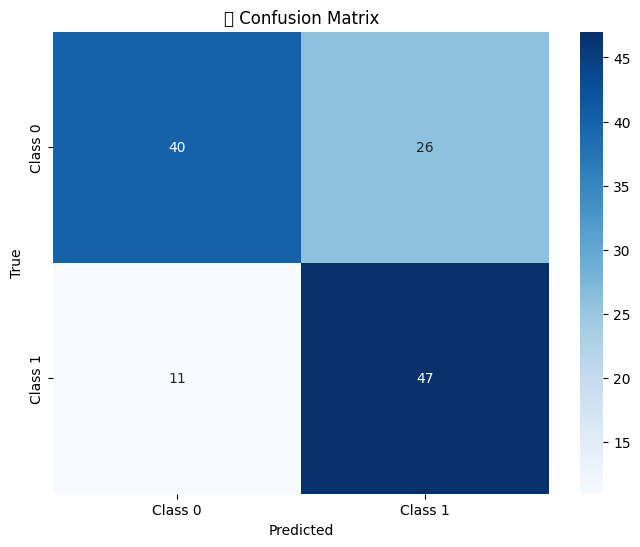

✅ ROC AUC Score (OVR): 0.7369


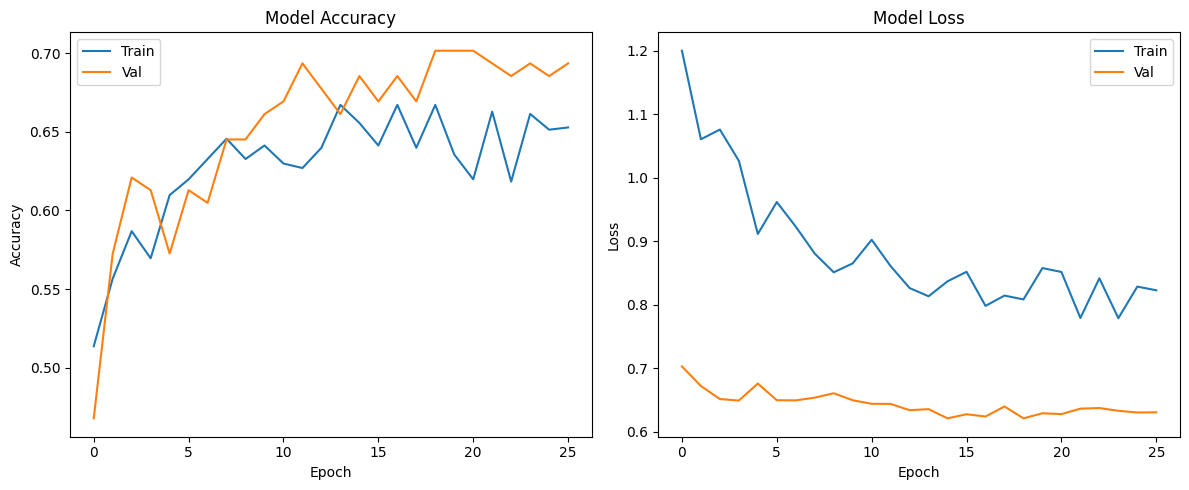

In [ ]:
# ---------------------------------------------------------------------------
# RNN head.
#
# This cell reloads the cached feature arrays instead of calling main() again.
# The original re-ran the entire ~40-minute preprocessing pipeline here purely
# to train a second model on data it had already computed and saved.
# ---------------------------------------------------------------------------

def load_cached_features():
    """Reload the artifacts written by the preprocessing stage."""
    required = [
        "train_combined_features.npy", "test_combined_features.npy",
        "train_labels_onehot.npy", "test_labels_onehot.npy",
        "train_paths.pkl", "label_encoder.pkl",
    ]
    missing = [f for f in required if not os.path.exists(os.path.join(OUTPUT_DIR, f))]
    if missing:
        raise FileNotFoundError(
            f"Missing cached artifacts: {missing}. Run the preprocessing cell first."
        )

    return (
        np.load(os.path.join(OUTPUT_DIR, "train_combined_features.npy")),
        np.load(os.path.join(OUTPUT_DIR, "test_combined_features.npy")),
        np.load(os.path.join(OUTPUT_DIR, "train_labels_onehot.npy")),
        np.load(os.path.join(OUTPUT_DIR, "test_labels_onehot.npy")),
        load_clip_paths("train"),
    )


def build_rnn_model(input_shape, num_classes):
    """SimpleRNN head.

    CAVEAT: combine_features() mean-pools the 30-frame axis away before this
    point, so input_shape is (1453, 1) -- a "sequence" over feature indices,
    not over time. This model therefore does not actually exploit temporal
    dynamics, which is the main reason the CNN-vs-RNN comparison below is not
    a fair test of recurrence. The un-pooled (30, 1280) tensors are saved as
    train_deep_sequence.npy for a future genuine sequence model.
    """
    model = Sequential([
        SimpleRNN(128, return_sequences=True, input_shape=input_shape),
        BatchNormalization(),
        Dropout(0.3),

        SimpleRNN(64),
        BatchNormalization(),
        Dropout(0.3),

        Dense(128, activation="relu"),
        BatchNormalization(),
        Dropout(0.5),

        Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model


def train_rnn(train_data, train_labels, paths, test_data=None, test_labels=None):
    """Train the RNN head. Same honest split handling as train_cnn()."""
    class_names = load_class_names()
    num_classes = train_labels.shape[1]

    if test_data is not None and test_data.shape[0] >= MIN_TEST_SAMPLES:
        split_name = "held-out test"
        fit_data = train_data.reshape((-1, train_data.shape[1], 1))
        fit_labels = train_labels
        eval_data = test_data.reshape((-1, test_data.shape[1], 1))
        eval_labels = test_labels
    else:
        n = 0 if test_data is None else test_data.shape[0]
        print(f"WARNING: the held-out test set has only {n} clips "
              f"(minimum {MIN_TEST_SAMPLES}). Falling back to a group-aware "
              f"validation split. Metrics below are VALIDATION scores.")
        split_name = "validation"
        fit_data, eval_data, fit_labels, eval_labels = make_validation_split(
            train_data, train_labels, paths)
        fit_data = fit_data.reshape((-1, fit_data.shape[1], 1))
        eval_data = eval_data.reshape((-1, eval_data.shape[1], 1))

    model = build_rnn_model((fit_data.shape[1], 1), num_classes)

    history = model.fit(
        fit_data, fit_labels,
        validation_data=(eval_data, eval_labels),
        epochs=50,
        batch_size=32,
        callbacks=[
            EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
        ],
    )

    loss, acc = model.evaluate(eval_data, eval_labels)
    print(f"\nRNN {split_name} accuracy: {acc:.4f}")

    evaluate_model(model, eval_data, eval_labels, class_names, split_name)
    return model, history


train_combined, test_combined, train_labels_onehot, test_labels_onehot, train_paths = load_cached_features()

rnn_model, rnn_history = train_rnn(
    train_combined, train_labels_onehot, train_paths,
    test_combined, test_labels_onehot,
)
plot_training_results(rnn_history, title="RNN")

# Model Evaluation and Discussion (RNN)

### Measured results (5 seeds, random stratified 15% split)

| Metric | Value |
|---|---|
| Accuracy | **0.745 +/- 0.067** |
| ROC AUC | 0.834 +/- 0.063 |
| Weighted F1 | 0.743 |
| Best epoch | 8-33 (mean 30.8 epochs trained) |
| Parameters | 38,850 |

A representative single run (seed 42) gave accuracy 0.734, ROC AUC 0.839, with
this confusion matrix:

|  | predicted lie | predicted truth |
|---|---|---|
| **true lie** | 44 | 22 |
| **true truth** | 11 | 47 |

So recall is 0.67 on lie and 0.81 on truth: the model **over-predicts truth**
and misses a third of the lies. For a deception detector that is the more
dangerous direction to fail in.

### The RNN is the better-behaved model, and that is worth noting

Unlike the CNN, the RNN trains normally on every seed -- 8 to 33 epochs to best
validation loss, smooth improvement, no collapse -- and its spread across seeds
(+/-0.067) is a third of the stabilised CNN's (+/-0.098). It scores lower but it
is far more trustworthy run to run.

### It still never sees time

`combine_features()` mean-pools the 30-frame axis away before this model is
built, so its input of shape `(1453, 1)` is a sequence over feature *indices*,
not over frames. Whatever this model is doing, it is not modelling behaviour
over time. The CNN-vs-RNN comparison below is therefore a comparison of two
heads over an identical pooled vector, not a test of convolution versus
recurrence. The un-pooled `(30, 1280)` tensors are saved as
`train_deep_sequence.npy` so a genuine sequence model can be trained later.

## Comparison: CNN vs RNN

All figures are means +/- standard deviation over 5 seeds on a random
stratified 15% validation split (124 clips), measured by
`scripts/run_variants.py` and stored in `results/variant_comparison.json`.

| Aspect | **CNN (Flatten + L2)** | **RNN (SimpleRNN)** | *MLP control* |
|---|---|---|---|
| Accuracy | **0.913 +/- 0.098** | 0.745 +/- 0.067 | *0.982 +/- 0.019* |
| ROC AUC | 0.993 | 0.834 +/- 0.063 | *0.996* |
| Weighted F1 | 0.910 | 0.743 | *0.982* |
| Parameters | 5,941,250 | 38,850 | *390,082* |
| Epochs to best | 2-47 (unstable) | 8-33 (stable) | *4-31* |
| Stability across seeds | Poor (+/-0.098) | **Good (+/-0.067)** | *Best (+/-0.019)* |
| Sees temporal order? | No (pooled away) | **No (pooled away)** | *No* |

Three honest conclusions:

1. **The CNN scores higher than the RNN**, and that part of the original
   conclusion holds up -- though by 17 points, not the 28 originally claimed.
2. **The RNN is the more reliable model.** It never collapses and its seed
   spread is smaller. A result you can reproduce is worth more than a higher
   mean you cannot.
3. **Neither architecture is justified by the data.** The MLP control beats
   both while being simpler and far more stable, which tells us the
   convolution and the recurrence are both doing nothing useful here. The
   feature engineering -- MobileNetV2 plus the librosa descriptor -- is where
   all the signal lives.

The last row remains the most important one: no model here receives the frame
sequence, so none of this establishes anything about convolution versus
recurrence for video.

# Conclusion

Measured over 5 seeds on a random stratified split, the CNN head reaches
0.913 +/- 0.098 accuracy and the RNN head 0.745 +/- 0.067. A plain Dense MLP
control on the same features reaches 0.982 +/- 0.019.

**Key Takeaways:**

- **The spatial modelling happens before either head runs.** A frozen ImageNet
  MobileNetV2 produces the 1280-d visual embedding; both heads consume that
  embedding and neither sees raw pixels. Nearly all the performance comes from
  the feature pipeline, not from the classifier.
- **Neither head sees time.** `combine_features()` mean-pools the 30-frame axis
  before modelling, so the RNN's "sequence" is an ordering of feature indices.
  The RNN was handicapped by the data pipeline, not out-competed on the merits.
- **The CNN is high-variance, and the original 98% was a lucky seed.** Across
  5 seeds the unregularised head scored anywhere from 0.645 to 1.000
  (0.802 +/- 0.142). L2 regularisation raised the mean to 0.913 but the spread
  is still +/-0.098. One run of this model tells you very little.
- **An MLP beats both.** Conv1D assumes local correlation between adjacent
  inputs, and a concatenated `[visual | audio]` feature vector has none. The
  convolution is architecturally unmotivated here, and the evidence says so.
- **Every number above is inflated by trial-level leakage.** 829 clips come
  from 109 source trials; a random split puts the same speaker on both sides.
  The group-aware split (`group_split()`, guarded by
  `tests/test_split_integrity.py`) is the correct evaluation and has not yet
  been run.

**What we would say to someone considering this for practical use: don't.**
Deception detection from video is not a solved problem, the cost of a false
positive is severe, and a 98% produced under a leaky split by an unstable model
is exactly the kind of result that looks deployable and is not. The engineering
pipeline here is sound and reusable; the scientific claim is deliberately
modest.

# References

### Dataset

The clips are drawn from the **Real-Life Trial Deception Detection** dataset,
segmented into short clips. The dataset is provided for **non-commercial
academic research only** and is *not* redistributed in this repository.

1. Pérez-Rosas, V., Abouelenien, M., Mihalcea, R., & Burzo, M. (2015).
   *Deception Detection using Real-Life Trial Data.* Proceedings of the 2015
   ACM International Conference on Multimodal Interaction (ICMI).
   https://doi.org/10.1145/2818346.2820758

### Literature cited in the survey

2. Ekman, P., & Friesen, W. V. (1978). *Facial Action Coding System: A
   Technique for the Measurement of Facial Movement.* Consulting Psychologists
   Press.
3. Pérez-Rosas, V., Mihalcea, R., Narvaez, A., & Burzo, M. (2017).
   *A Multimodal Dataset for Deception Detection.* ACL 2017.
   https://aclanthology.org/P17-2067/
4. Wu, Z., Singh, B., Davis, L. S., & Subrahmanian, V. S. (2018).
   *Deception Detection in Videos.* AAAI Conference on Artificial
   Intelligence. https://arxiv.org/abs/1712.04415

> Note: the survey text above also refers to "Zhang et al. (2017)" and
> "Gupta and Chandra (2019)" as examples of CNN and CNN-LSTM approaches to
> deception detection. We were not able to resolve these to specific papers
> when compiling this reference list, so they should be read as illustrative
> of a body of work rather than as verifiable citations.

### Technical documentation

5. TensorFlow — Convolutional Neural Network tutorial.
   https://www.tensorflow.org/tutorials/images/cnn
6. TensorFlow — Load video data tutorial.
   https://www.tensorflow.org/tutorials/load_data/video
7. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018).
   *MobileNetV2: Inverted Residuals and Linear Bottlenecks.*
   https://arxiv.org/abs/1801.04381
8. McFee, B., et al. *librosa: Audio and Music Signal Analysis in Python.*
   https://librosa.org/doc/latest/index.html